# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed. 

There are four datasets: 
1) bank-additional-full.csv with all examples (41188) and 20 inputs, ordered by date (from May 2008 to November 2010), very close to the data analyzed in [Moro et al., 2014]
2) bank-additional.csv with 10% of the examples (4119), randomly selected from 1), and 20 inputs.
3) bank-full.csv with all examples and 17 inputs, ordered by date (older version of this dataset with less inputs). 
4) bank.csv with 10% of the examples and 17 inputs, randomly selected from 3 (older version of this dataset with less inputs). 
The smallest datasets are provided to test more computationally demanding machine learning algorithms (e.g., SVM). 

The classification goal is to predict if the client will subscribe (yes/no) a term deposit (variable y).

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [61]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from sklearn.model_selection import GridSearchCV
import plotly.express as px

# for creating the profile report of data 
from ydata_profiling import ProfileReport

import warnings
warnings.filterwarnings('ignore')


In [62]:
df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [63]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [64]:
#show all columns in the dataset
pd.set_option('display.max_columns', None)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [65]:
df.describe()


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [66]:
#Duration calls v.s job roles
 
fig = px.box(df, x="job", y="duration", color="y")
fig.update_traces(quartilemethod="exclusive") # or "inclusive", or "linear" by default
fig.show()

In [67]:
#Campaign vs Duration calls

fig = px.scatter(df, x="campaign", y="duration", color="y")
fig.show()

In [68]:
# monthly distribution of calls
fig = px.histogram(df, x='month', color='y', nbins=12)
fig.update_layout(title='Monthly Distribution of Calls', xaxis_title='Month', yaxis_title='Count')
fig.show()

<Axes: xlabel='cons.price.idx', ylabel='marital'>

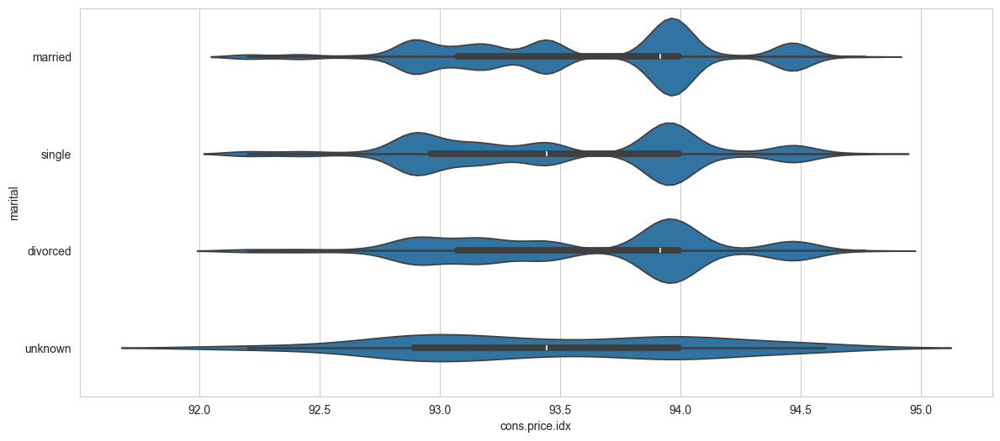

In [69]:
sns.violinplot( y=df["marital"], x=df["cons.price.idx"] )

Numeric features correlation with target:


y_binary          1.000000
duration          0.405274
previous          0.230181
cons.conf.idx     0.054878
age               0.030399
campaign         -0.066357
cons.price.idx   -0.136211
emp.var.rate     -0.298334
euribor3m        -0.307771
pdays            -0.324914
nr.employed      -0.354678
Name: y_binary, dtype: float64

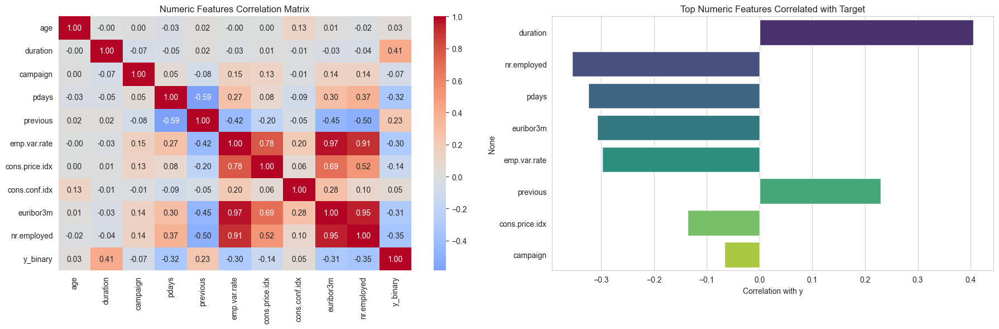

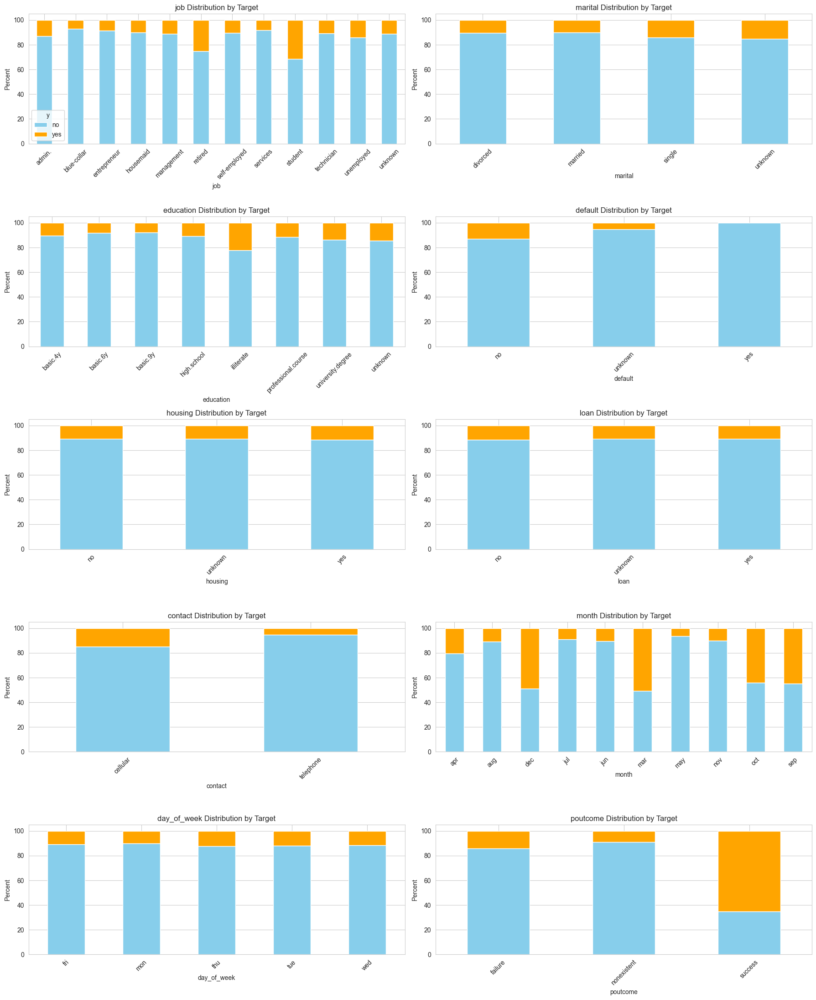

Top categorical levels positively associated with yes:


poutcome_success    0.316269
contact_cellular    0.144773
month_mar           0.144014
month_oct           0.137366
month_sep           0.126067
default_no          0.099344
job_student         0.093955
job_retired         0.092221
month_dec           0.079303
month_apr           0.076136
dtype: float64

Top categorical levels negatively associated with yes:


education_basic.6y     -0.023517
month_jul              -0.032230
job_services           -0.032301
marital_married        -0.043398
education_basic.9y     -0.045135
job_blue-collar        -0.074423
default_unknown        -0.099293
month_may              -0.108271
contact_telephone      -0.144773
poutcome_nonexistent   -0.193507
dtype: float64

In [70]:
# EDA: feature-target relationships and correlations



## - remove the bar graphs in this EDA - Rajeev action 

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

# 1. Numeric correlation with target
y_binary = (df['y'] == 'yes').astype(int)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

corr_matrix = pd.concat([df[numeric_cols], y_binary.rename('y_binary')], axis=1).corr()
corr_target = corr_matrix['y_binary'].sort_values(ascending=False)

print("Numeric features correlation with target:")
display(corr_target)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Numeric Features Correlation Matrix")

top_numeric = corr_target.drop('y_binary').abs().sort_values(ascending=False).head(8).index
sns.barplot(x=corr_target.loc[top_numeric].values, y=top_numeric, palette="viridis", ax=axes[1])
axes[1].set_title("Top Numeric Features Correlated with Target")
axes[1].set_xlabel("Correlation with y")
plt.tight_layout()
plt.show()

# 2. Categorical feature relationship with target
categorical_cols = df.select_dtypes(include=['object']).columns.drop('y')

fig, axs = plt.subplots(5, 2, figsize=(18, 22))
axs = axs.ravel()

for i, col in enumerate(categorical_cols):
    ct = pd.crosstab(df[col], df['y'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axs[i], color=['skyblue', 'orange'], legend=(i == 0))
    axs[i].set_title(f"{col} Distribution by Target")
    axs[i].set_ylabel("Percent")
    axs[i].set_xlabel(col)
    axs[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 3. Categorical one-hot correlations
cat_dummies = pd.get_dummies(df[categorical_cols], drop_first=False)
cat_corr = cat_dummies.corrwith(y_binary).sort_values(ascending=False)

print("Top categorical levels positively associated with yes:")
display(cat_corr.head(10))

print("Top categorical levels negatively associated with yes:")
display(cat_corr.tail(10))

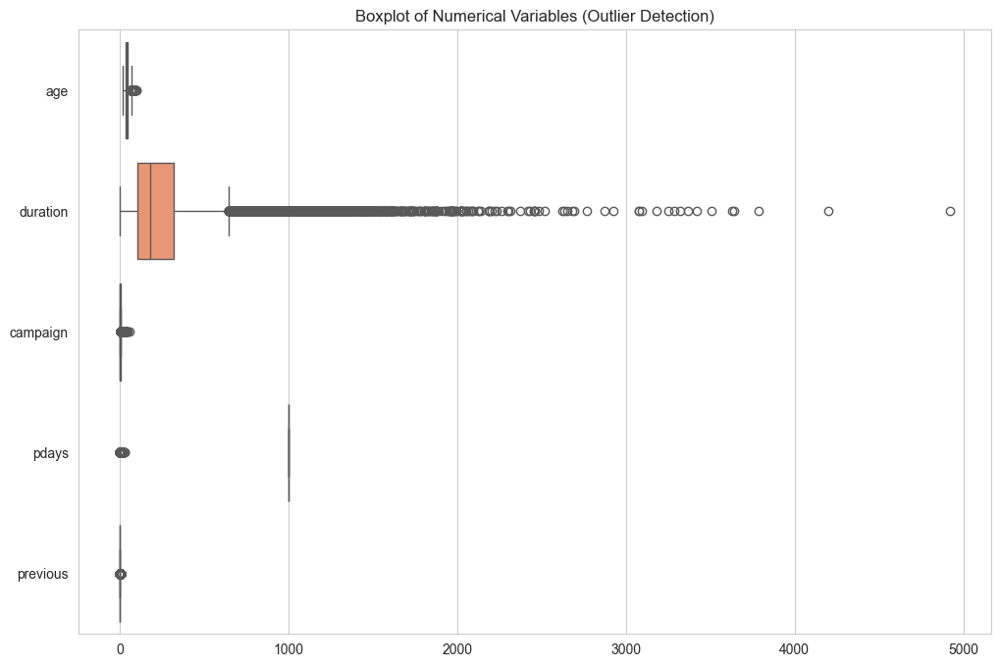

In [71]:
# Box plots to detect outliers
plt.figure(figsize=(12, 8))
sns.boxplot(data=df.select_dtypes(include=['int64']), orient="h", palette="Set2")
plt.title("Boxplot of Numerical Variables (Outlier Detection)")
plt.show()

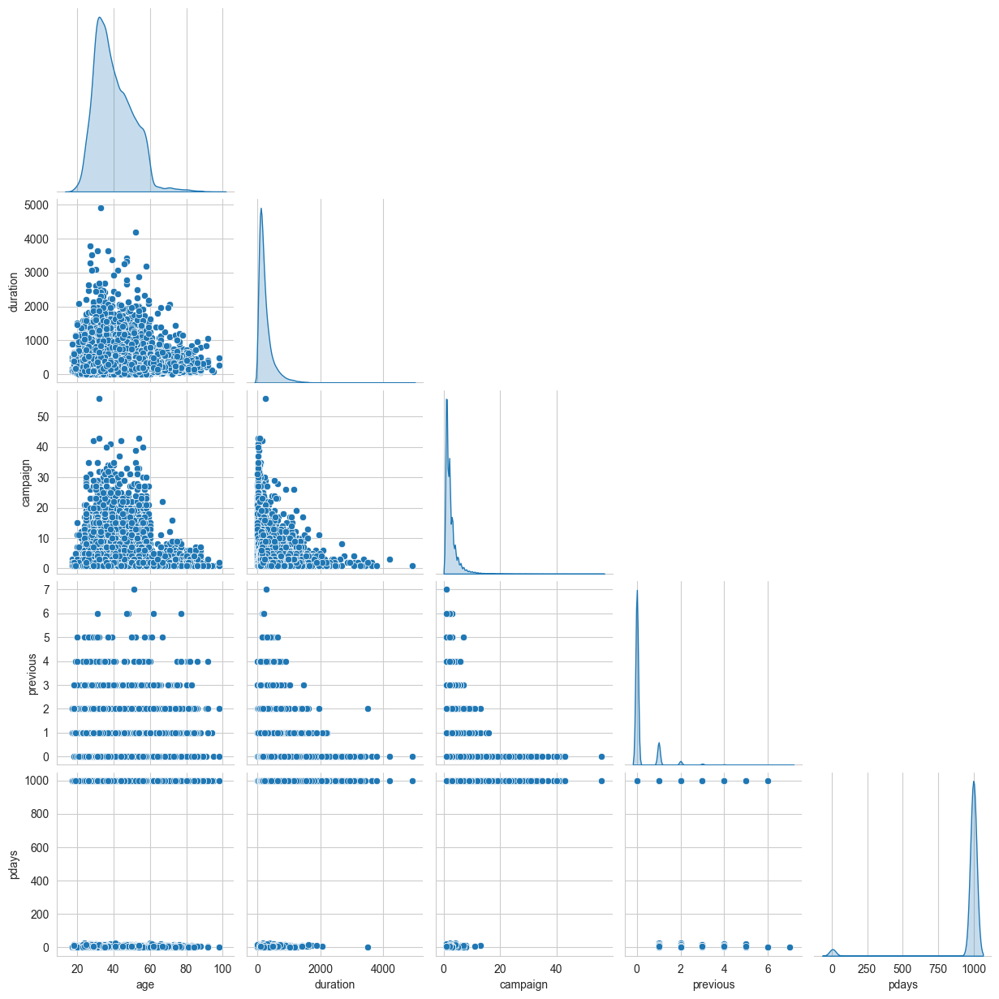

In [72]:
#need to true up the column names for pair plot 
 
selected_features = ["age", "duration", "campaign", "previous", "pdays"]
sns.pairplot(df[selected_features], diag_kind="kde", corner=True)

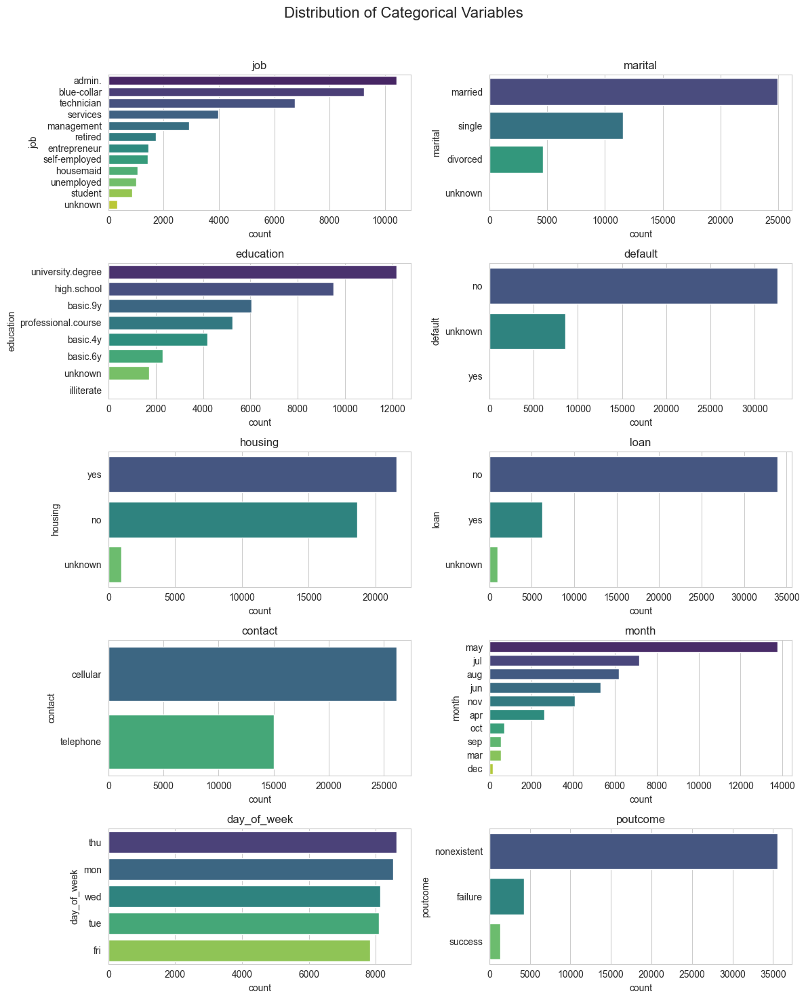

In [73]:
# Plot count plots for categorical variables
categorical_columns = df.select_dtypes(include=['object']).columns

fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(12, 15))
fig.suptitle("Distribution of Categorical Variables", fontsize=16)

'''for ax, col in zip(axes.flatten(), categorical_columns):
    sns.countplot(y=X[col], ax=ax, order=X[col].value_counts().index, palette="viridis")
    ax.set_title(col)'''

#loop across all the categorical columns and plot countplots

for ax, col in zip(axes.flatten(), categorical_columns):
    sns.countplot(y=df[col], ax=ax, order=df[col].value_counts().index, palette="viridis")
    ax.set_title(col)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [74]:
profile = ProfileReport(df, title="Bank Loan Data Profiling Report", explorative=True)
profile.to_file("data/bank_loan_profile_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 219105.43it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [75]:
profile

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

### Business objective of the task 

The overall goal / business problem is to predict whether a client will subscribe to a term deposit based on various features. The target variable is 'y', which indicates whether the client subscribed ('yes') or not ('no').

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [77]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [78]:
# get details of unique values for Job and Education ,  'marital', 'default' , 'housing' and 'loan' columns.

print("Unique values in 'job' column:", df['job'].unique())
print("Unique values in 'education' column:", df['education'].unique())
print("Unique values in 'marital' column:", df['marital'].unique())
print("Unique values in 'default' column:", df['default'].unique())
print("Unique values in 'housing' column:", df['housing'].unique())
print("Unique values in 'loan' column:", df['loan'].unique())



Unique values in 'job' column: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']
Unique values in 'education' column: ['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']
Unique values in 'marital' column: ['married' 'single' 'divorced' 'unknown']
Unique values in 'default' column: ['no' 'unknown' 'yes']
Unique values in 'housing' column: ['no' 'yes' 'unknown']
Unique values in 'loan' column: ['no' 'yes' 'unknown']


In [79]:
# find our all columns with "unknown" value and its % of total values in that column 
for col in df.columns:
    if df[col].dtype == 'object':
        unknown_count = (df[col] == 'unknown').sum()
        total_count = len(df[col])
        unknown_percentage = (unknown_count / total_count) * 100
        print(f"Column: {col}, Unknown Count: {unknown_count}, Percentage: {unknown_percentage:.2f}%")  

Column: job, Unknown Count: 330, Percentage: 0.80%
Column: marital, Unknown Count: 80, Percentage: 0.19%
Column: education, Unknown Count: 1731, Percentage: 4.20%
Column: default, Unknown Count: 8597, Percentage: 20.87%
Column: housing, Unknown Count: 990, Percentage: 2.40%
Column: loan, Unknown Count: 990, Percentage: 2.40%
Column: contact, Unknown Count: 0, Percentage: 0.00%
Column: month, Unknown Count: 0, Percentage: 0.00%
Column: day_of_week, Unknown Count: 0, Percentage: 0.00%
Column: poutcome, Unknown Count: 0, Percentage: 0.00%
Column: y, Unknown Count: 0, Percentage: 0.00%


### Observation - Default – coulmn has very high % of unknowns, Along with that it the rest of customers that dont default ( plot above) and inly 3 with default as yes. Thus representing a significant skewed in favor of individuals with no credit default.

In [80]:
'''#what is the % of unknown values in marital', 'default' , 'housing' and 'loan' columns.
for col in ['job', 'education', 'marital', 'default', 'housing', 'loan']:
    unknown_percentage = (df[col] == 'unknown').mean() * 100
    print(f"Percentage of 'unknown' values in '{col}' column: {unknown_percentage:.2f}%")'''

'#what is the % of unknown values in marital\', \'default\' , \'housing\' and \'loan\' columns.\nfor col in [\'job\', \'education\', \'marital\', \'default\', \'housing\', \'loan\']:\n    unknown_percentage = (df[col] == \'unknown\').mean() * 100\n    print(f"Percentage of \'unknown\' values in \'{col}\' column: {unknown_percentage:.2f}%")'

In [81]:
# To handle the unknown values in job and education columns? we will impute them with the most frequent value in the respective column. 
# impute unknown values in job column
most_frequent_job = df['job'].mode()[0]
df['job'] = df['job'].replace('unknown', most_frequent_job)
# impute unknown values in education column
most_frequent_education = df['education'].mode()[0]
df['education'] = df['education'].replace('unknown', most_frequent_education) 
# impute unknown values in marital column
most_frequent_marital = df['marital'].mode()[0]
df['marital'] = df['marital'].replace('unknown', most_frequent_marital)
# impute unknown values in housing column
most_frequent_housing = df['housing'].mode()[0]
df['housing'] = df['housing'].replace('unknown', most_frequent_housing)
  

In [82]:
# do feature engineering for job and education columns
# for job column, we can group the jobs into 4 categories: blue-collar, white-collar, self-employed, and unemployed
# for education column, we can group the education levels into 3 categories: primary, secondary, and tertiary
# mapping for job column
job_mapping = {
    'admin.': 'white-collar',
    'blue-collar': 'blue-collar',
    'entrepreneur': 'self-employed',
    'housemaid': 'unemployed',
    'management': 'white-collar',
    'retired': 'unemployed',
    'self-employed': 'self-employed',
    'services': 'white-collar',
    'student': 'unemployed',
    'technician': 'blue-collar',
    'unemployed': 'unemployed',
}
# mapping for education column
education_mapping = {
    'basic.4y': 'primary',
    'basic.6y': 'primary',
    'basic.9y': 'primary',
    'high.school': 'secondary',
    'illiterate': 'primary',
    'professional.course': 'tertiary',
    'university.degree': 'tertiary',
}

In [83]:
#udpate the job and education columns with the new category mapping
df['job'] = df['job'].map(job_mapping)
df['education'] = df['education'].map(education_mapping)

In [84]:
#handle pdays column values of 999 and setting it back to 0
df['pdays'] = df['pdays'].replace(999, 0)

In [85]:
print("Unique values in 'job' column:", df['job'].unique())
print("Unique values in 'education' column:", df['education'].unique())

Unique values in 'job' column: ['unemployed' 'white-collar' 'blue-collar' 'self-employed']
Unique values in 'education' column: ['primary' 'secondary' 'tertiary']


In [86]:
#ordinal encoding for all categorical features
from sklearn.preprocessing import OrdinalEncoder
ordinal_cols = df.select_dtypes(include=['object']).columns.drop('y')
encoder = OrdinalEncoder()
df[ordinal_cols] = encoder.fit_transform(df[ordinal_cols])
# Encode target variable
df['y'] = (df['y'] == 'yes').astype(int)
df.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,2.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,261,1,0,0,1.0,1.1,93.994,-36.4,4.857,5191.0,0
1,57,3.0,1.0,1.0,1.0,0.0,0.0,1.0,6.0,1.0,149,1,0,0,1.0,1.1,93.994,-36.4,4.857,5191.0,0
2,37,3.0,1.0,1.0,0.0,1.0,0.0,1.0,6.0,1.0,226,1,0,0,1.0,1.1,93.994,-36.4,4.857,5191.0,0
3,40,3.0,1.0,0.0,0.0,0.0,0.0,1.0,6.0,1.0,151,1,0,0,1.0,1.1,93.994,-36.4,4.857,5191.0,0
4,56,3.0,1.0,1.0,0.0,0.0,2.0,1.0,6.0,1.0,307,1,0,0,1.0,1.1,93.994,-36.4,4.857,5191.0,0


In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  float64
 2   marital         41188 non-null  float64
 3   education       41188 non-null  float64
 4   default         41188 non-null  float64
 5   housing         41188 non-null  float64
 6   loan            41188 non-null  float64
 7   contact         41188 non-null  float64
 8   month           41188 non-null  float64
 9   day_of_week     41188 non-null  float64
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  float64
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [88]:
#we will standardize numeric features

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('y')
scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,1.533034,0.305277,-0.279803,-1.346134,-0.513600,-1.100814,-0.452491,1.31827,0.762558,-0.718834,0.010471,-0.565922,-0.164012,-0.349494,0.192622,0.648092,0.722722,0.886447,0.71246,0.33168,0
1,1.628993,1.035204,-0.279803,-0.186182,1.945327,-1.100814,-0.452491,1.31827,0.762558,-0.718834,-0.421501,-0.565922,-0.164012,-0.349494,0.192622,0.648092,0.722722,0.886447,0.71246,0.33168,0
2,-0.290186,1.035204,-0.279803,-0.186182,-0.513600,0.908418,-0.452491,1.31827,0.762558,-0.718834,-0.124520,-0.565922,-0.164012,-0.349494,0.192622,0.648092,0.722722,0.886447,0.71246,0.33168,0
3,-0.002309,1.035204,-0.279803,-1.346134,-0.513600,-1.100814,-0.452491,1.31827,0.762558,-0.718834,-0.413787,-0.565922,-0.164012,-0.349494,0.192622,0.648092,0.722722,0.886447,0.71246,0.33168,0
4,1.533034,1.035204,-0.279803,-0.186182,-0.513600,-1.100814,2.311440,1.31827,0.762558,-0.718834,0.187888,-0.565922,-0.164012,-0.349494,0.192622,0.648092,0.722722,0.886447,0.71246,0.33168,0


In [89]:
profile_clean = ProfileReport(df, title="Bank Loan Cleaned Data Profiling Report", explorative=True)
profile_clean.to_file("data/bank_loan_cleaned_profile_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 199.56it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [90]:
profile_clean

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [91]:
X = df.drop('y', axis = 1)
y = df['y']

In [92]:
X_train,  X_test, y_train, y_test =  train_test_split(X, y, test_size = 0.2, random_state = 42)

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [93]:
# Calculate baseline performance
baseline_accuracy = (y_test == 0).sum() / len(y_test)
print(f"Baseline Accuracy (predicting majority class): {baseline_accuracy:.4f}")
print(f"Percentage of negative class (y=0) in test set: {baseline_accuracy*100:.2f}%")
print(f"Percentage of positive class (y=1) in test set: {(1-baseline_accuracy)*100:.2f}%")

Baseline Accuracy (predicting majority class): 0.8865
Percentage of negative class (y=0) in test set: 88.65%
Percentage of positive class (y=1) in test set: 11.35%


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [94]:
#create a simple model using logistic regression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)
y_proba = lr_model.predict_proba(X_test)[:, 1]


### Problem 9: Score the Model

What is the accuracy of your model?

In [95]:
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba))

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      7303
           1       0.67      0.41      0.51       935

    accuracy                           0.91      8238
   macro avg       0.80      0.69      0.73      8238
weighted avg       0.90      0.91      0.90      8238

Confusion Matrix:
[[7110  193]
 [ 548  387]]
ROC AUC Score: 0.9315527059790095


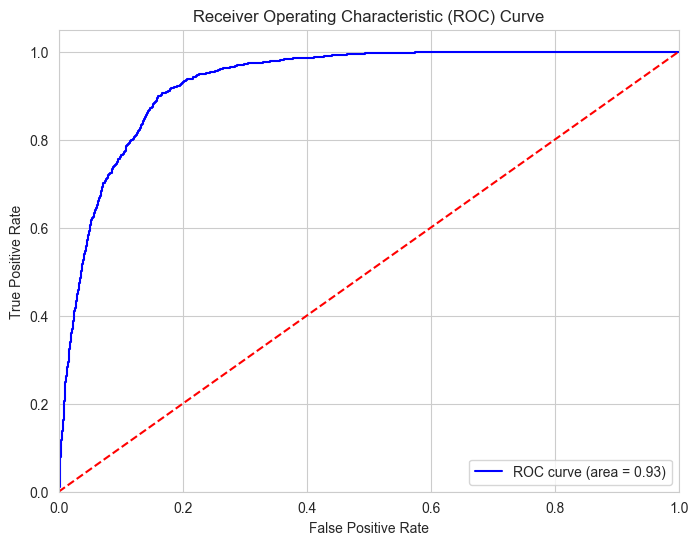

In [96]:
#plotting ROC curve
from sklearn.metrics import roc_curve, auc
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [97]:
random_state = 42

In [98]:
models = {
    "Logistic Regression": LogisticRegression(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(),
    "SVM": SVC(kernel='linear')
}

In [99]:
#initiating a dictionary to store the results
results = {"Model": [], "Train Time": [], "Train Accuracy": [], "Test Accuracy": []}
results 

{'Model': [], 'Train Time': [], 'Train Accuracy': [], 'Test Accuracy': []}

In [100]:
import time


for name, model in models.items():
    print(f"Evaluating {name}...")
    start_time = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_time
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_proba = model.decision_function(X_test)

    results["Model"].append(name)
    results["Train Time"].append(train_time)
    results["Train Accuracy"].append(model.score(X_train, y_train))
    results["Test Accuracy"].append(model.score(X_test, y_test))

    

Evaluating Logistic Regression...
Evaluating K-Nearest Neighbors...
Evaluating Decision Tree...
Evaluating SVM...


In [101]:
results_df = pd.DataFrame(results)
results_df

,Model,Train Time,Train Accuracy,Test Accuracy
0,Logistic Regression,0.063772,0.909833,0.910051
1,K-Nearest Neighbors,0.001674,0.927921,0.898519
2,Decision Tree,0.083159,1.000000,0.883952
3,SVM,8.479739,0.904947,0.904588


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [102]:
#hyperparameter tuning for logistic regression

param_grid = {'C': [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=random_state), param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)
print("Best Logistic Regression parameters:", grid_search.best_params_)
best_lr = grid_search.best_estimator_
y_pred_lr = best_lr.predict(X_test)
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

Best Logistic Regression parameters: {'C': 0.01}
Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      7303
           1       0.67      0.40      0.50       935

    accuracy                           0.91      8238
   macro avg       0.80      0.69      0.73      8238
weighted avg       0.90      0.91      0.90      8238



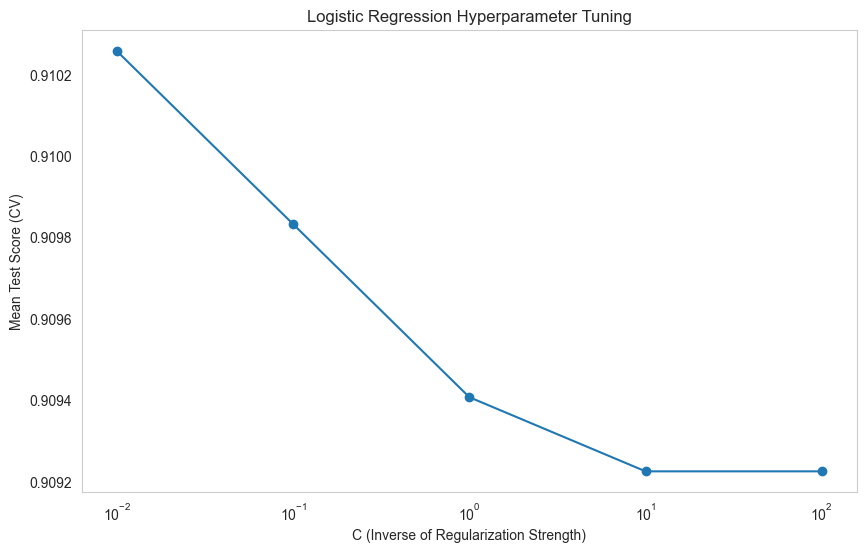

In [103]:
#plot the results of the hyperparameter tuning for logistic regression
results_df_lr = pd.DataFrame(grid_search.cv_results_)
results_df_lr = results_df_lr.sort_values(by='mean_test_score', ascending=False)
plt.figure(figsize=(10, 6))
plt.plot(results_df_lr['param_C'], results_df_lr['mean_test_score'], marker='o')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('Mean Test Score (CV)')
plt.title('Logistic Regression Hyperparameter Tuning')
plt.grid()
plt.show()

In [104]:
#hyperparameter tuning for KNN

param_grid = {
    'n_neighbors': list(range(1, 21)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)
print("Best KNN parameters:", grid_search.best_params_)
best_knn = grid_search.best_estimator_
y_pred_knn = best_knn.predict(X_test)
print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

Best KNN parameters: {'metric': 'manhattan', 'n_neighbors': 19, 'weights': 'uniform'}
KNN Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7303
           1       0.64      0.27      0.38       935

    accuracy                           0.90      8238
   macro avg       0.78      0.63      0.66      8238
weighted avg       0.88      0.90      0.88      8238



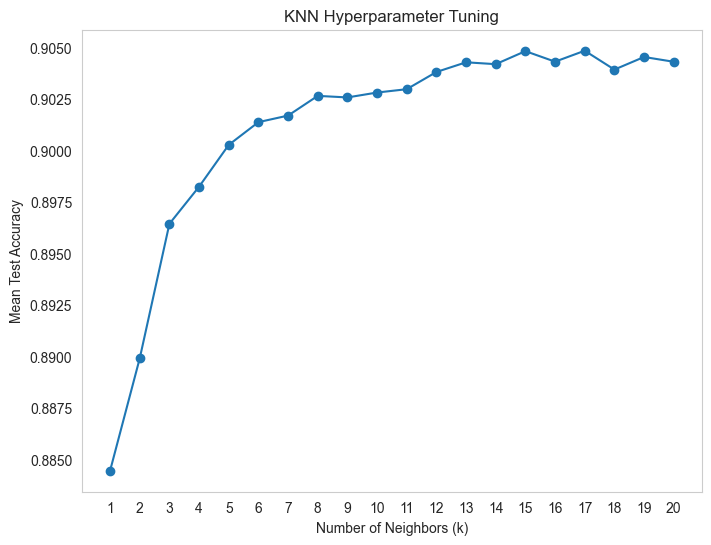

In [105]:
#plot for KNN for the neighbors vs accuracy
knn_results = pd.DataFrame(grid_search.cv_results_)
plt.figure(figsize=(8, 6))
knn_results.groupby('param_n_neighbors')['mean_test_score'].mean().plot(marker='o')
plt.title('KNN Hyperparameter Tuning')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Test Accuracy')
plt.xticks(param_grid['n_neighbors'])
plt.grid()
plt.show()

In [106]:
#hyperparameter tuning for decision tree
param_grid_dt = {'max_depth': [None, 5, 10, 15]}
grid_search_dt = GridSearchCV(DecisionTreeClassifier(random_state=random_state), param_grid_dt, cv=5, n_jobs=-1)
grid_search_dt.fit(X_train, y_train)
print("Best Decision Tree parameters:", grid_search_dt.best_params_)
best_dt = grid_search_dt.best_estimator_
y_pred_dt = best_dt.predict(X_test)
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))


Best Decision Tree parameters: {'max_depth': 5}
Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      7303
           1       0.65      0.54      0.59       935

    accuracy                           0.92      8238
   macro avg       0.80      0.75      0.77      8238
weighted avg       0.91      0.92      0.91      8238



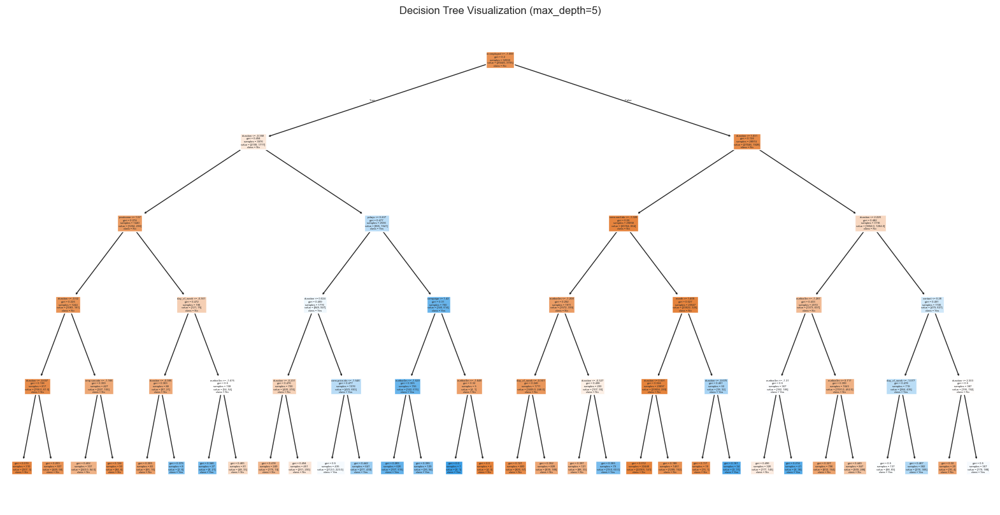

In [107]:
#plot the decision tree
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10))
plot_tree(best_dt, filled=True, feature_names=X.columns, class_names=['No', 'Yes'], max_depth=5)
plt.title("Decision Tree Visualization (max_depth=5)")
plt.show()

In [108]:
#hyperparameter tuning for SVM  

param_grid_svm = {'C': [0.01, 0.1, 1, 10, 100], 'kernel': ['linear', 'rbf']}
grid_search_svm = GridSearchCV(SVC(random_state=random_state), param_grid_svm, cv=5, n_jobs=-1)
grid_search_svm.fit(X_train, y_train)
print("Best SVM parameters:", grid_search_svm.best_params_)
best_svm = grid_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test)
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))


Best SVM parameters: {'C': 1, 'kernel': 'rbf'}
SVM Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      7303
           1       0.67      0.40      0.50       935

    accuracy                           0.91      8238
   macro avg       0.80      0.69      0.73      8238
weighted avg       0.90      0.91      0.90      8238



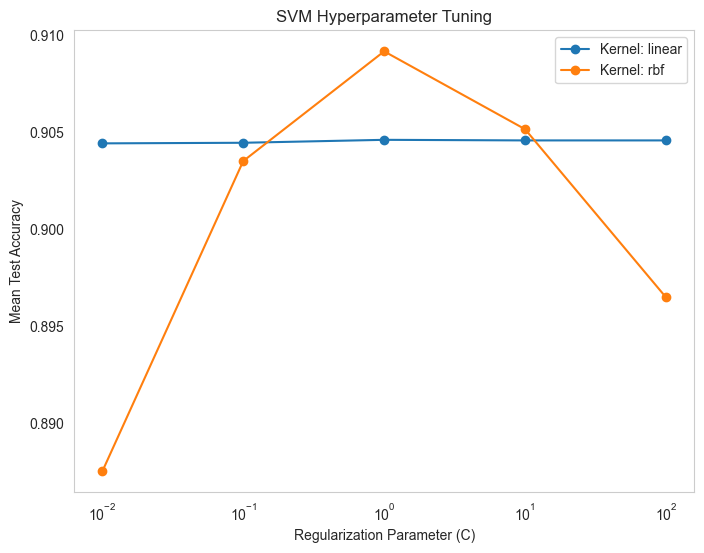

In [109]:
#plot rbf vs linear for SVM
svm_results = pd.DataFrame(grid_search_svm.cv_results_)
plt.figure(figsize=(8, 6))
for kernel in param_grid_svm['kernel']:
    subset = svm_results[svm_results['param_kernel'] == kernel]
    plt.plot(subset['param_C'], subset['mean_test_score'], marker='o', label=f'Kernel: {kernel}')
plt.xscale('log')
plt.title('SVM Hyperparameter Tuning')
plt.xlabel('Regularization Parameter (C)')
plt.ylabel('Mean Test Accuracy')
plt.legend()
plt.grid()
plt.show()

In [110]:
#append the hyper parameter tuning results to the results dataframe
results["Model"].append("Logistic Regression (Tuned)")
results["Train Time"].append(grid_search.refit_time_)
results["Train Accuracy"].append(best_lr.score(X_train, y_train))
results["Test Accuracy"].append(best_lr.score(X_test, y_test))

results["Model"].append("KNN (Tuned)")
results["Train Time"].append(grid_search.refit_time_)
results["Train Accuracy"].append(best_knn.score(X_train, y_train))
results["Test Accuracy"].append(best_knn.score(X_test, y_test))

results["Model"].append("Decision Tree (Tuned)")
results["Train Time"].append(grid_search_dt.refit_time_)
results["Train Accuracy"].append(best_dt.score(X_train, y_train))
results["Test Accuracy"].append(best_dt.score(X_test, y_test))

results["Model"].append("SVM (Tuned)")
results["Train Time"].append(grid_search_svm.refit_time_)
results["Train Accuracy"].append(best_svm.score(X_train, y_train))
results["Test Accuracy"].append(best_svm.score(X_test, y_test))


In [111]:
#converting the dictionary into a dataframe
results_df = pd.DataFrame(results)
results_df

,Model,Train Time,Train Accuracy,Test Accuracy
0,Logistic Regression,0.063772,0.909833,0.910051
1,K-Nearest Neighbors,0.001674,0.927921,0.898519
2,Decision Tree,0.083159,1.000000,0.883952
3,SVM,8.479739,0.904947,0.904588
4,Logistic Regression (Tuned),0.004809,0.910379,0.909687
5,KNN (Tuned),0.004809,0.910926,0.899854
6,Decision Tree (Tuned),0.037161,0.917329,0.915149
7,SVM (Tuned),5.308188,0.919393,0.909565


In [112]:
#sort out the results dataframe by test accuracy
results_df_acc = results_df.sort_values(by='Test Accuracy', ascending=False)
results_df_acc

,Model,Train Time,Train Accuracy,Test Accuracy
6,Decision Tree (Tuned),0.037161,0.917329,0.915149
0,Logistic Regression,0.063772,0.909833,0.910051
4,Logistic Regression (Tuned),0.004809,0.910379,0.909687
7,SVM (Tuned),5.308188,0.919393,0.909565
3,SVM,8.479739,0.904947,0.904588
5,KNN (Tuned),0.004809,0.910926,0.899854
1,K-Nearest Neighbors,0.001674,0.927921,0.898519
2,Decision Tree,0.083159,1.000000,0.883952


In [113]:
#sodfting on train time
results_df_time = results_df.sort_values(by='Train Time', ascending=True)
results_df_time

,Model,Train Time,Train Accuracy,Test Accuracy
1,K-Nearest Neighbors,0.001674,0.927921,0.898519
4,Logistic Regression (Tuned),0.004809,0.910379,0.909687
5,KNN (Tuned),0.004809,0.910926,0.899854
6,Decision Tree (Tuned),0.037161,0.917329,0.915149
0,Logistic Regression,0.063772,0.909833,0.910051
2,Decision Tree,0.083159,1.000000,0.883952
7,SVM (Tuned),5.308188,0.919393,0.909565
3,SVM,8.479739,0.904947,0.904588


In [114]:
# add a row for baseline accuracy into the results dataframe
baseline_row = {
    "Model": "Baseline (Majority Class)",
    "Train Time": 0,
    "Train Accuracy": baseline_accuracy,
    "Test Accuracy": baseline_accuracy
}

new_row_df = pd.DataFrame([baseline_row])

results_df = pd.concat([results_df, new_row_df], ignore_index=True)

results_df

,Model,Train Time,Train Accuracy,Test Accuracy
0,Logistic Regression,0.063772,0.909833,0.910051
1,K-Nearest Neighbors,0.001674,0.927921,0.898519
2,Decision Tree,0.083159,1.000000,0.883952
3,SVM,8.479739,0.904947,0.904588
4,Logistic Regression (Tuned),0.004809,0.910379,0.909687
5,KNN (Tuned),0.004809,0.910926,0.899854
6,Decision Tree (Tuned),0.037161,0.917329,0.915149
7,SVM (Tuned),5.308188,0.919393,0.909565
8,Baseline (Majority Class),0.000000,0.886502,0.886502


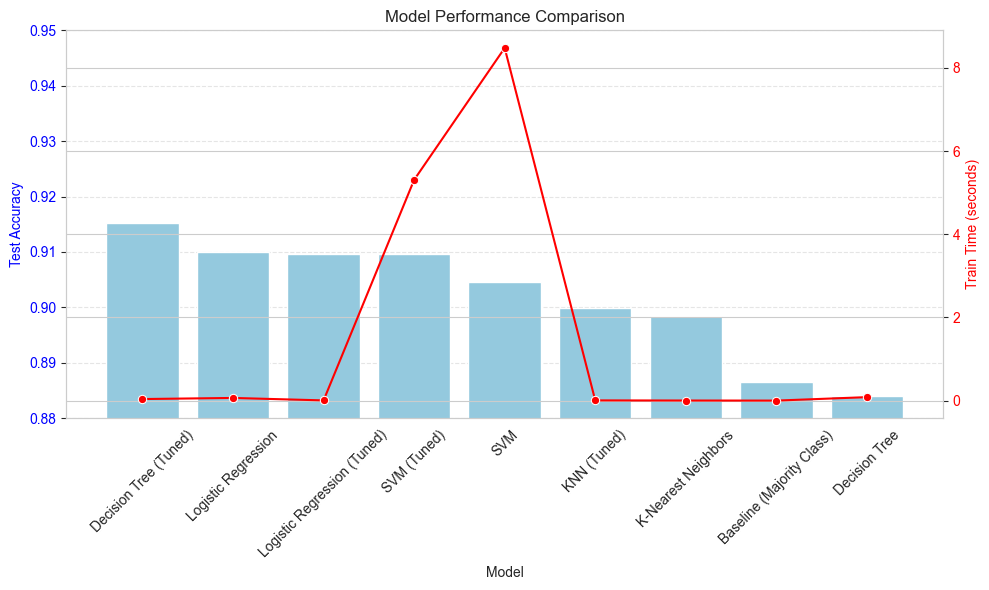

In [115]:
# plot a graph with bars for test accuracy and line graph for train time in a single graph
# zoom on accuracy between 0.85 and 0.95

results_df = results_df.sort_values('Test Accuracy', ascending=False).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(10, 6))
sns.barplot(x='Model', y='Test Accuracy', data=results_df, ax=ax1, color='skyblue')
ax1.set_xlabel('Model')
ax1.set_ylabel('Test Accuracy', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(0.88, 0.95)

ax2 = ax1.twinx()
sns.lineplot(x='Model', y='Train Time', data=results_df, ax=ax2, color='red', marker='o')
ax2.set_ylabel('Train Time (seconds)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Model Performance Comparison')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



##### Questions

##### This criterion is linked to a Learning Outcome Findings:


## The Baseline accuracy for the given data set is 

### Upon doing the analysis using the classifiers (k-nearest neighbors, logistic regression, decision trees, and support vector machines) with their default setting we observe that Logistic regression takes low time and gives the best test data set accuracy of 0.910415

### However, once we tune these classifiers for their hyper parameters its observed that Desision tree with takes low training time and gives the best accuracy of 0.915149 wtih max tree depth = 5

### The next steps would be to 
- check if the (loan) default - unknown can be addressed to remove the bias towards yes in the current dataset 

- eliminate the ourliers by considering only 75th %ile and rerun the complete analysis and see if we have an improvement in the accuracy score

- evaluate other classifiers (either direclty or a hybrid approach) and explore if a good balance betwwen training time with better Test acurracy is feasible v/s the currently used classifiers 